<a href="https://colab.research.google.com/github/aryasure/BA305-UK-Mapping-Musem-Project/blob/main/Desciptive_Analysis_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# BA305 Project - PCA
# Descriptive Question: What types of museums are located in areas experiencing multiple forms of socioeconomic deprivation?

In [17]:
# load libraries
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# load dataset
from google.colab import files
uploaded = files.upload()
filename = next(iter(uploaded))

museum_df = pd.read_csv(filename)
museum_df.head()
print(museum_df.shape)

museum_df.info()
print(museum_df.nunique())

# remove missing values
cols = ['area_deprivation_index_crime', 'area_deprivation_index_education',
        'area_deprivation_index_employment', 'area_deprivation_index_health',
        'area_deprivation_index_housing', 'area_deprivation_index_income', 'area_deprivation_index_services']

# convert columns to numeric
for col in cols:
    museum_df[col] = pd.to_numeric(museum_df[col], errors='coerce')

# drop rows missing in deprivation measures
museum_clean = museum_df.dropna(subset=cols)
museum_clean = museum_clean.reset_index(drop=True)

print("cleaned dataset:", museum_clean.shape)

# create dataframe for PCA
museum_mdf = museum_clean[cols].copy()
museum_mdf.head()

Saving museums_cleaned.csv to museums_cleaned (5).csv
(4190, 29)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4190 entries, 0 to 4189
Data columns (total 29 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   museum_id                            4190 non-null   object 
 1   name_of_museum                       4190 non-null   object 
 2   address_line_1                       3749 non-null   object 
 3   address_line_2                       1375 non-null   object 
 4   village_town_or_city                 4186 non-null   object 
 5   postcode                             4190 non-null   object 
 6   latitude                             4190 non-null   float64
 7   longitude                            4190 non-null   float64
 8   admin_area                           4190 non-null   object 
 9   accreditation                        4190 non-null   object 
 10  governance                     

,area_deprivation_index_crime,area_deprivation_index_education,area_deprivation_index_employment,area_deprivation_index_health,area_deprivation_index_housing,area_deprivation_index_income,area_deprivation_index_services
0,3.0,1.0,2.0,1.0,4.0,5.0,5.0
1,8.0,9.0,8.0,8.0,6.0,8.0,4.0
2,9.0,8.0,10.0,8.0,5.0,8.0,1.0
3,10.0,7.0,7.0,8.0,7.0,8.0,4.0
4,1.0,6.0,3.0,2.0,1.0,3.0,4.0


                                   area_deprivation_index_crime  \
area_deprivation_index_crime                               1.00   
area_deprivation_index_education                           0.40   
area_deprivation_index_employment                          0.48   
area_deprivation_index_health                              0.58   
area_deprivation_index_housing                             0.34   
area_deprivation_index_income                              0.50   
area_deprivation_index_services                           -0.30   

                                   area_deprivation_index_education  \
area_deprivation_index_crime                                   0.40   
area_deprivation_index_education                               1.00   
area_deprivation_index_employment                              0.73   
area_deprivation_index_health                                  0.68   
area_deprivation_index_housing                                 0.18   
area_deprivation_index_income        

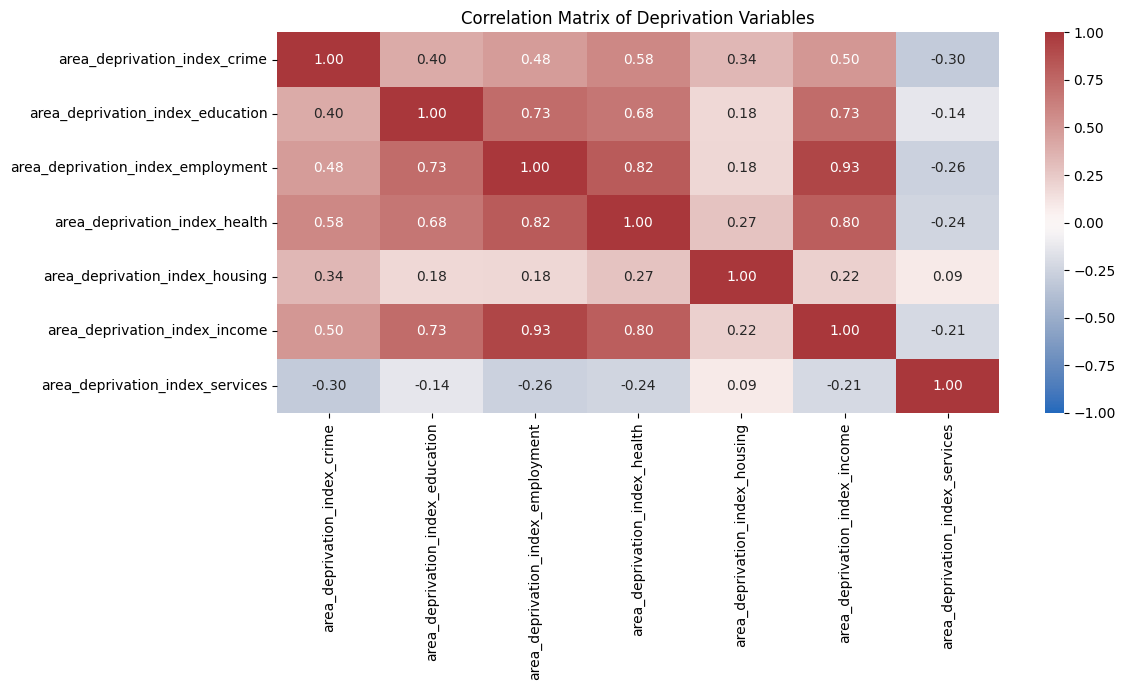

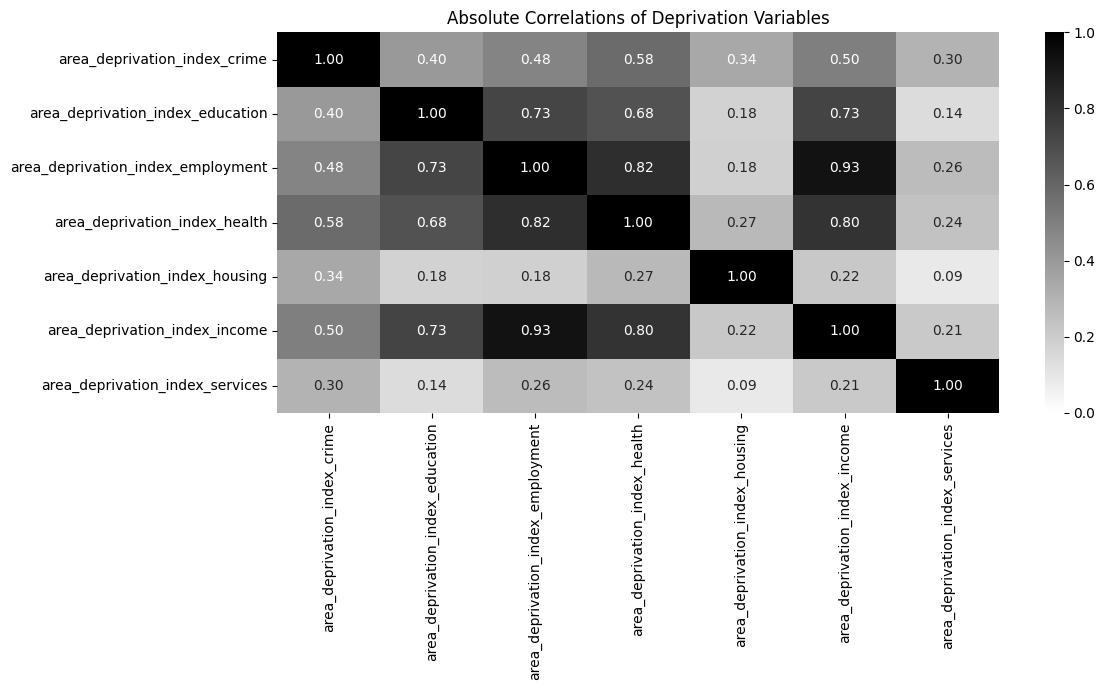

In [8]:
# looking at the correlation between variables

# correlation matrix
corr_mat = museum_mdf.corr()
print(corr_mat.round(2))

# correlation heatmap
plt.figure(figsize=(12, 7))
sns.heatmap(corr_mat, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap='vlag')
plt.title('Correlation Matrix of Deprivation Variables')
plt.tight_layout()
plt.show()

# absolute correlation heatmap
plt.figure(figsize=(12, 7))
sns.heatmap(np.absolute(corr_mat), annot=True, fmt=".2f", vmin=0, vmax=1, cmap="gray_r")
plt.title('Absolute Correlations of Deprivation Variables')
plt.tight_layout()
plt.show()

In [9]:
# scaling data and running PCA

# check spread of original variables
spread = museum_mdf.agg(['min', 'max', 'mean', 'std']).T.sort_values('std', ascending=False)
print(spread.round(2))

# standardize variables
scaler = StandardScaler()
scaled_df = pd.DataFrame(scaler.fit_transform(museum_mdf), columns=museum_mdf.columns)
scaled_df.head()
print(scaled_df.agg(['mean', 'std']).round(3))

# run PCA using the 7 deprivation variables
pcs = PCA(n_components=7)
scores = pcs.fit_transform(scaled_df)

# name components PC1 - PC7
pc_names = ['PC' + str(i+1) for i in range(pcs.n_components_)]

scores_df = pd.DataFrame(scores, columns=pc_names)

# eigenvalues
eig = pcs.explained_variance_

# summary of explained variance
summary_df = pd.DataFrame({
    'Eigenvalue': eig,
    '% of variance': pcs.explained_variance_ratio_ * 100,
    'Cumulative %': np.cumsum(pcs.explained_variance_ratio_) * 100
}, index=pc_names)
print(summary_df.round(3))

# PCA weights
weights_df = pd.DataFrame(pcs.components_.T, index=museum_mdf.columns, columns=pc_names)
print("PCA Weights:")
print(weights_df.round(3))

                                   min   max  mean   std
area_deprivation_index_crime       1.0  10.0  5.43  3.07
area_deprivation_index_services    1.0  10.0  4.78  3.01
area_deprivation_index_health      1.0  10.0  6.02  2.82
area_deprivation_index_employment  1.0  10.0  6.08  2.76
area_deprivation_index_housing     1.0  10.0  3.97  2.75
area_deprivation_index_income      1.0  10.0  5.99  2.62
area_deprivation_index_education   1.0  10.0  6.04  2.61
      area_deprivation_index_crime  area_deprivation_index_education  \
mean                          -0.0                              -0.0   
std                            1.0                               1.0   

      area_deprivation_index_employment  area_deprivation_index_health  \
mean                               -0.0                           -0.0   
std                                 1.0                            1.0   

      area_deprivation_index_housing  area_deprivation_index_income  \
mean                            -

Component Matrix:
                                    PC1   PC2   PC3   PC4   PC5   PC6   PC7
area_deprivation_index_crime       0.69  0.09 -0.49  0.51  0.08 -0.08  0.01
area_deprivation_index_education   0.81  0.01  0.30 -0.09  0.49  0.02  0.00
area_deprivation_index_employment  0.93 -0.09  0.20 -0.08 -0.19 -0.13  0.19
area_deprivation_index_health      0.91  0.02  0.05  0.05 -0.16  0.38 -0.03
area_deprivation_index_housing     0.34  0.77 -0.43 -0.33  0.00 -0.02  0.00
area_deprivation_index_income      0.92 -0.03  0.21 -0.05 -0.16 -0.20 -0.17
area_deprivation_index_services   -0.33  0.70  0.56  0.29 -0.05 -0.01  0.01


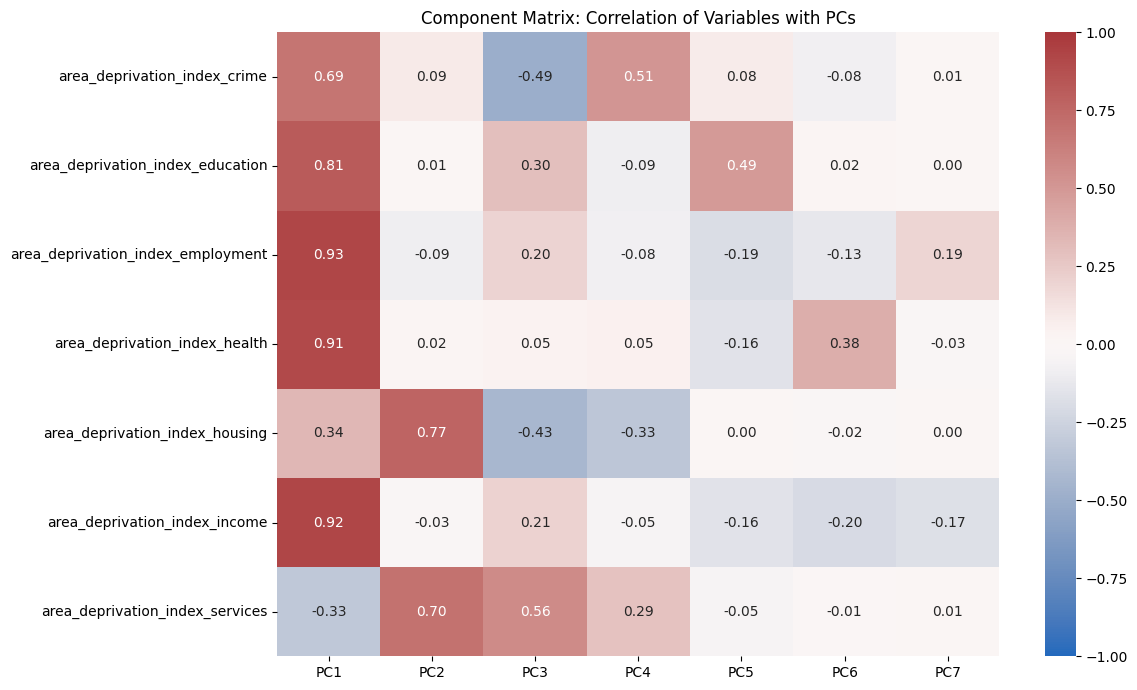

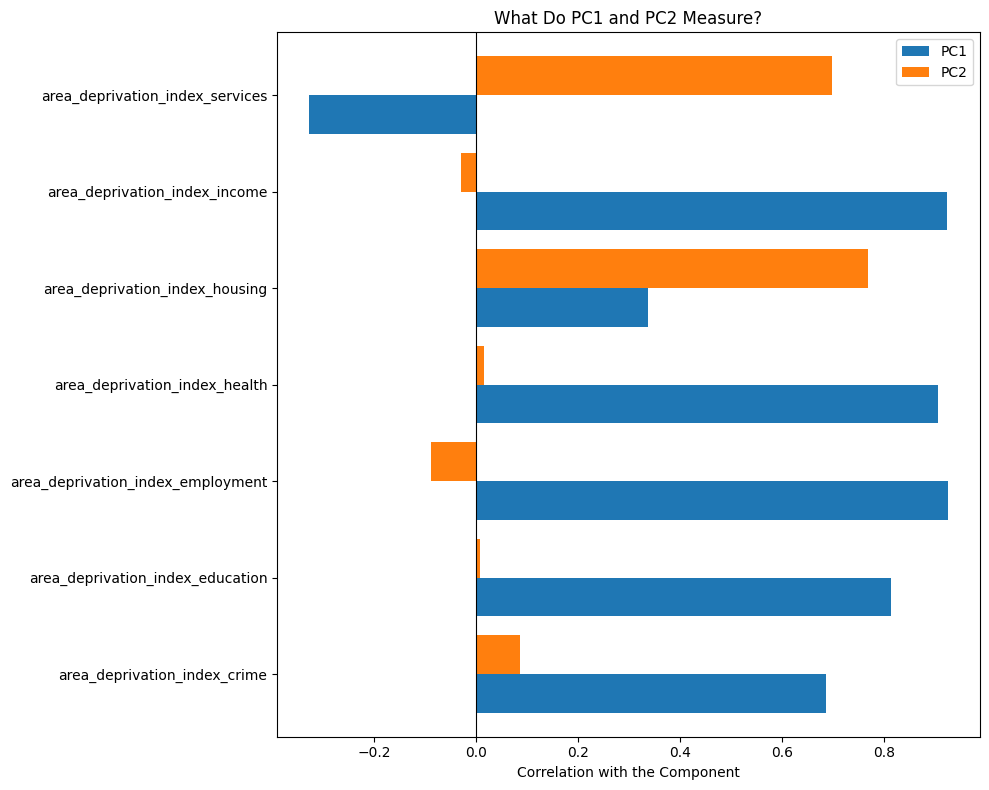

In [10]:
# component matrix

# correlations between original variables and PCs
loadings_df = pd.concat([scores_df, scaled_df], axis=1).corr().loc[museum_mdf.columns, pc_names]
print("Component Matrix:")
print(loadings_df.round(2))

# heatmap of component matrix
plt.figure(figsize=(12, 7))
sns.heatmap(loadings_df, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap='vlag')
plt.title('Component Matrix: Correlation of Variables with PCs')
plt.tight_layout()
plt.show()

# bar chart for PC1 and PC2
loadings_df[['PC1', 'PC2']].plot.barh(figsize=(10, 8), width=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Correlation with the Component')
plt.title('What Do PC1 and PC2 Measure?')
plt.tight_layout()
plt.show()

PC1    3.89
PC2    1.10
PC3    0.93
PC4    0.48
PC5    0.33
PC6    0.21
PC7    0.07


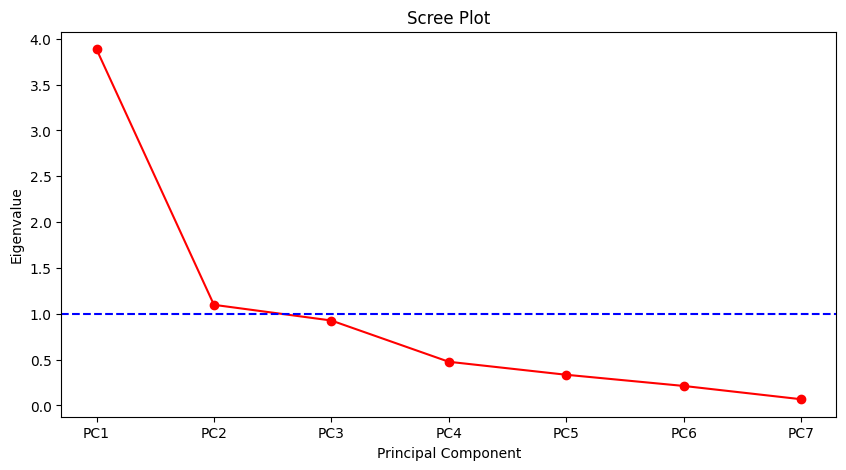

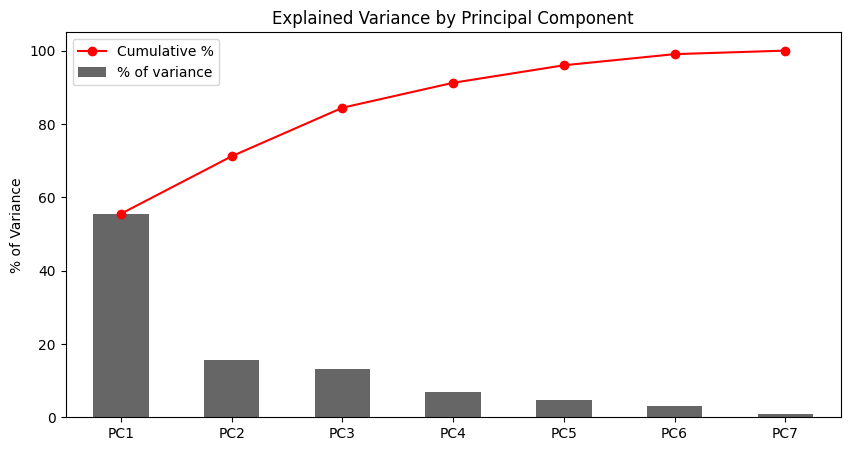

Components with eigenvalues > 1: 2
Components needed for 70% variance: 2


In [11]:
# looking at components needed

# eigenvalues
print(summary_df['Eigenvalue'].round(2).to_string())

# scree plot
ax = summary_df['Eigenvalue'].plot(marker='o', color='red', figsize=(10, 5))
ax.axhline(y=1, color='b', linestyle='--')
ax.set_title('Scree Plot')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Eigenvalue')
plt.show()

# explained variance plot
ax = summary_df['% of variance'].plot.bar(figsize=(10, 5), color='0.4')
summary_df['Cumulative %'].plot(marker='o', color='red', ax=ax)
ax.set_ylabel('% of Variance')
ax.set_title('Explained Variance by Principal Component')
ax.legend(['Cumulative %', '% of variance'])
plt.show()

# number of PCs with eigenvalues > 1
print("Components with eigenvalues > 1:", sum(eig > 1))

# number of PCs needed to explain at least 70%
n_70 = np.searchsorted(np.cumsum(pcs.explained_variance_ratio_), 0.70) + 1
print("Components needed for 70% variance:", n_70)

In [12]:
# keeping the first components

# use number of PCs needed for 70% variance
pcs_reduced = PCA(n_components=n_70)
principalComponents = pcs_reduced.fit_transform(scaled_df)

# create dataframe with component scores
factor_names = ['F' + str(i+1) for i in range(n_70)]
principalDF = pd.DataFrame(principalComponents.round(3), columns=factor_names)
print(principalDF.head())

# confirm PCs are uncorrelated
print(principalDF.corr().round(4))

# merge scores with museum information
museum_df_aug = pd.concat([museum_clean, principalDF], axis=1)
museum_df_aug.head()

      F1     F2
0 -2.774  0.088
1  1.937  0.378
2  2.336 -0.592
3  1.739  0.723
4 -2.364 -0.978
     F1   F2
F1  1.0  0.0
F2  0.0  1.0


,museum_id,name_of_museum,address_line_1,address_line_2,village_town_or_city,postcode,latitude,longitude,admin_area,accreditation,...,area_deprivation_index_services,area_geodemographic_group,area_geodemographic_group_code,area_geodemographic_subgroup,area_geodemographic_subgroup_code,area_geodemographic_supergroup,area_geodemographic_supergroup_code,operating_status,F1,F2
0,mm.New.1,Titanic Belfast,1 Olympic Way,NaN,Belfast,BT3 9EP,54.608080,-5.909915,/Northern Ireland/Belfast (NI Loc Gov District),Unaccredited,...,5.0,Larger Towns and Cities,2ar,Larger Towns and Cities,2a1r,Business Education and Heritage Centres,2r,open,-2.774,0.088
1,mm.aim.1230,The Woodland Heritage Museum,NaN,Brokerswood,nr Westbury,BA13 4EH,51.270903,-2.231863,/England/South West (English Region)/Wiltshire...,Unaccredited,...,4.0,Country Living,7ar,Country Living,7a1r,Town and Country Living,7r,closed,1.937,0.378
2,mm.domus.WM019,Warwickshire Museum Of Rural Life,Warwick College of Agriculture,Horticulture & Equine Studies,Moreton Morrell,CV35 9BL,52.197146,-1.555528,/England/West Midlands (English Region)/Warwic...,Unaccredited,...,1.0,English and Welsh Countryside,3ar,Older Farming Communities,3a1r,Countryside Living,3r,open,2.336,-0.592
3,mm.aim.0485,Jet Age Museum,57 Crown Drive,Bishops Cleeve,Cheltenham,GL52 8TA,51.940092,-2.060766,/England/South West (English Region)/Glouceste...,Accredited,...,4.0,Country Living,7ar,Country Living,7a1r,Town and Country Living,7r,open,1.739,0.723
4,mm.aim.0486,Jewish Military Museum,c/o Jewish Museum,Raymond Burton House,London,NW1 7NB,51.537163,-0.144517,/England/London (English Region)/Camden (Londo...,Unaccredited,...,4.0,London Cosmopolitan,5ar,London Cosmopolitan,5a1r,London Cosmopolitan,5r,closed,-2.364,-0.978


In [13]:
# visualizations using PC1 AND PC2

# hover scatter plot by museum size
fig = px.scatter(museum_df_aug, x='F1', y='F2', color='size', hover_name='name_of_museum',
    labels={'F1': 'First Principal Component', 'F2': 'Second Principal Component'},
    title='UK Museums on Their First Two Principal Components')
fig.show()

In [14]:
# PCA by museum subject matter

# select 8 most common museum subject categories
top_subjects = (museum_df_aug['subject_matter'].value_counts().head(8).index)
subject_df = museum_df_aug[museum_df_aug['subject_matter'].isin(top_subjects)].copy()

# hover PCA scatter plot
fig = px.scatter(subject_df, x='F1', y='F2', color='subject_matter', hover_name='name_of_museum',
    labels={'F1': 'First Principal Component', 'F2': 'Second Principal Component'},
    title='PCA of Deprivation by Museum Subject Matter')
fig.show()

                                    Museum_Count  Mean_F1  Median_F1  Mean_F2
subject_matter                                                               
Mixed-Encyclopaedic                          117   -1.403     -1.772   -0.104
Arts-Fine_and_decorative_arts                194   -0.389     -0.482   -0.229
Other                                         79   -0.382     -0.276   -0.272
Local_Histories                              883   -0.329     -0.242    0.378
Mixed-Other                                   84   -0.298     -0.223   -0.136
Buildings-Houses-Medium_houses                72   -0.085      0.491   -0.051
Transport-Trains_and_railways                137   -0.034      0.232    0.197
Leisure_and_sport-Toys_and_models             56   -0.016      0.096    0.014
War_and_conflict-Castles_and_forts            65    0.000      0.275   -0.131
War_and_conflict-Regiment                    129    0.024      0.260    0.089
Personality-Literary                          82    0.270      0

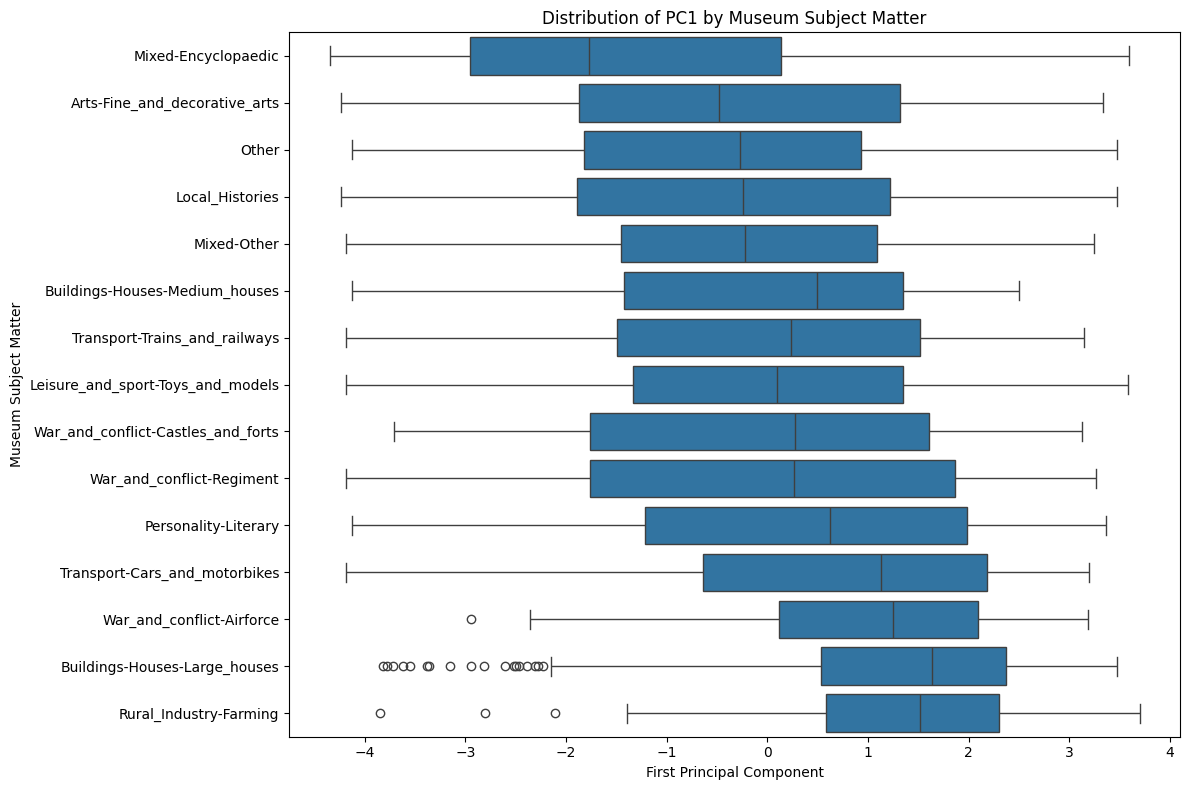

In [15]:
# compare PCA scores by museum subject
subject_summary = (museum_df_aug.groupby('subject_matter')
    .agg(Museum_Count=('F1', 'size'), Mean_F1=('F1', 'mean'), Median_F1=('F1', 'median'), Mean_F2=('F2', 'mean'))
    .query('Museum_Count >= 50')
    .sort_values('Mean_F1'))
print(subject_summary.round(3))

# plot comparison boxplot
plt.figure(figsize=(12, 8))
sns.boxplot(data=museum_df_aug[museum_df_aug['subject_matter'].isin(subject_summary.index)], x='F1', y='subject_matter', order=subject_summary.index)
plt.title('Distribution of PC1 by Museum Subject Matter')
plt.xlabel('First Principal Component')
plt.ylabel('Museum Subject Matter')
plt.tight_layout()
plt.show()

In [16]:
# compare museum size and governance
print("Museum size:")
print(museum_df_aug.groupby('size')[['F1', 'F2']].agg(['mean', 'median', 'std', 'count']).round(3))

print("\nGovernance:")
print(museum_df_aug.groupby('governance')[['F1', 'F2']].agg(['mean', 'median', 'std', 'count']).round(3))



Museum size:
           F1                         F2                    
         mean median    std count   mean median    std count
size                                                        
huge    1.339  1.592  1.282    12 -0.935 -1.152  0.573    12
large  -0.020  0.258  1.981   539 -0.302 -0.438  1.021   539
medium -0.293 -0.107  2.065  1012 -0.015 -0.046  1.013  1012
small   0.113  0.356  1.921  2579  0.073  0.034  1.055  2579

Governance:
                                              F1                         F2  \
                                            mean median    std count   mean   
governance                                                                    
Government-Cadw                           -0.498 -1.221  2.178     3  0.675   
Government-Local_Authority                -1.040 -1.308  1.966   913  0.142   
Government-National                        0.649  0.808  1.683    82 -0.484   
Government-Other                           1.013  2.204  2.038     8 -0.5